# Two-sector primitive CNOT — Stage 2: hub circuit at fixed gate density

Stage 2 of `plans/xz_noise_hub_cnot.md` with a gap that does not depend on the code size, simulated with `cnot_primitive_xz.jl` (`SCHEDULE=hub`; local runs from `jobs/cnot_primitive_xz_hub_local.jl` with `HUB_GAP=k` and `HUB_N_LIST="L 2L"`).

Circuit: the hub A (always the target) does `N` noisy CNOT rounds with fresh partners, one every `k + 1` rounds, with the same `k` for every `L`. The number of CNOTs grows with the code size, `N = L` and `N = 2L`, so the gate density on A and the aspect ratio of the circuit are fixed. Each partner gets `d = L` rounds, its CNOT round, and `d` rounds, then readout; A gets `d` rounds before its first CNOT and `d` after its last. Noise: single-qubit depolarizing `p`, measurement `q = p`, two-qubit depolarizing `p2 = 10p` at each CNOT; primitive rule mirrored per sector.

Metrics:

- **fixed-aspect failure probability** `P_total(N = cL)` (any block, either sector) and its finite-size crossing: the Lake-style threshold of a circuit whose length grows with `L` at a fixed gate density;
- **own faults per circuit by sector** (hub X, hub Z, and the partners' X and Z summed over partners), from the logical-frame snapshots: the same fixed-aspect normalization, block by block;
- **per-gate rate** `eps_CNOT = 1 - (1 - P(N))^(1/N)` at `N = L` (Google's single-point formula with `B = 1`). The decay fit `1 - P(N) = B (1 - eps)^N` over `N = L, 2L` checks `B`; it is unusable where `N = 2L` saturates;
- **suppression factor** `Lambda_CNOT` from `ln eps_CNOT` against `(L+1)/2`, and the crossing of `eps_CNOT`. At a fixed density these are per-gate normalizations of a circuit whose length grows with `L`, so they are cross-checks, not the threshold.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

PROJECT_DIR = next(
    (path for path in (Path.cwd(), Path.cwd().parent) if (path / "notebooks/analysis_utils.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Run this notebook from projects/mp-decoder or projects/mp-decoder/notebooks.")
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from analysis_utils import (
    RateEstimate,
    display_finite_size_scaling_fit,
    display_fit_summary,
    fit_finite_size_scaling,
    fit_lambda,
    hub_gate_rates,
    hub_rate_grids,
    lambda_ratios,
    load_ft_scan,
    load_hub_records,
    rates_as_scan,
    single_point_rate,
)

GAP = "1"   # fixed gap k of this scan (ordinary hub rounds between CNOTs)
MIN_L = 7  # smallest L in the main fits
HUB_ROOT = PROJECT_DIR / "results/cnot_primitive_xz/hub"
HUB_DIR = HUB_ROOT / f"k_{GAP}"
ASPECTS = {"N = L": "NL", "N = 2L": "N2L"}

groups = load_hub_records(HUB_DIR)
L_VALUES = sorted({key[1] for key in groups})
N_BY_L = {L: sorted({key[3] for key in groups if key[1] == L}) for L in L_VALUES}
ALL_P = sorted({key[2] for key in groups})
# keep only error rates where every (L, N) point exists
P_VALUES = [p for p in ALL_P if all((GAP, L, p, N) in groups for L in L_VALUES for N in N_BY_L[L])]
if len(P_VALUES) < len(ALL_P):
    print("incomplete p (left out):", sorted(set(ALL_P) - set(P_VALUES)))
print(f"k = {GAP}: {len(groups)} (L, p, N) points from {sum(g['files'] for g in groups.values())} files")
print("L:", L_VALUES)
print("p:", P_VALUES)
print("N per L:", N_BY_L)

k = 1: 100 (L, p, N) points from 100 files
L: [5, 7, 9, 11, 13]
p: [0.003, 0.004, 0.0045, 0.005, 0.0055, 0.006, 0.0065, 0.007, 0.008, 0.009]
N per L: {5: [5, 10], 7: [7, 14], 9: [9, 18], 11: [11, 22], 13: [13, 26]}


## 1. Fixed-aspect failure probability

Total failure probability (any block, either sector) with `N = L` and `N = 2L` CNOTs. At a fixed gate density the circuit volume grows with `L`, so below threshold the curves for larger `L` should fall below those for smaller `L`, as in a memory experiment with `T ∝ L`.

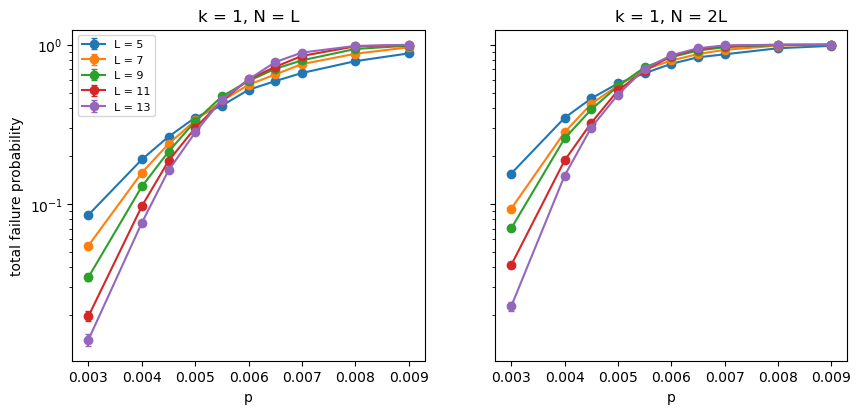

In [2]:
aspect_scans = {
    label: load_ft_scan(HUB_DIR / sub, p_values=P_VALUES, L_values=L_VALUES, expected_repeats=1,
                        result_pattern="2d_XZ_*.txt", success_field="Ft", scan_label=f"hub k={GAP}, {label}")
    for label, sub in ASPECTS.items()
}
fig, axes = plt.subplots(1, len(aspect_scans), figsize=(5 * len(aspect_scans), 4.3), sharey=True)
for ax, (label, scan) in zip(np.atleast_1d(axes), aspect_scans.items()):
    est = scan.rate()
    for i, L in enumerate(L_VALUES):
        ax.errorbar(P_VALUES, est.values[i], yerr=est.errors[i], fmt="o-", capsize=2, label=f"L = {L}")
    ax.set_yscale("log")
    ax.set_xlabel("p")
    ax.set_title(f"k = {GAP}, {label}")
np.atleast_1d(axes)[0].set_ylabel("total failure probability")
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.show()

Finite-size crossing of `P_total` at each aspect ratio (model `A + B x + C x^2`, `x = (p - p_c) L^(1/nu)`), and the pairwise crossings of consecutive sizes (linear interpolation; the bracket is the 16-84% range of a parametric bootstrap).

#### Finite-size scaling fit: P_total, N = L

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.005, 0.007]$ and $L \in [7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.00547(5) |
| $p_c$ (%) | 0.547(5) |
| $\nu$ | 1.4(1) |
| $A$ | 0.45(1) |
| $B$ | 55(6) |
| $C$ | -807(206) |
| $\chi^2 / \mathrm{dof}$ | 20.25 / 15 = 1.35 |
| goodness-of-fit $p$-value | 0.163 |

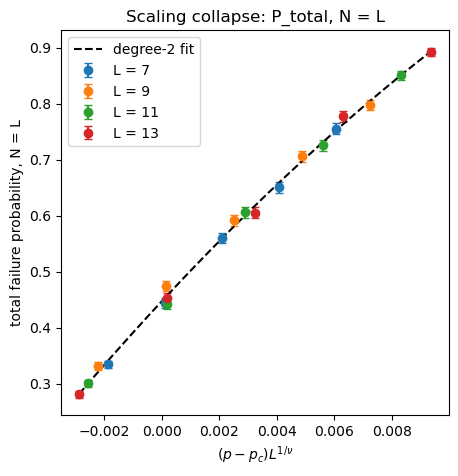

#### Finite-size scaling fit: P_total, N = 2L

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.005, 0.007]$ and $L \in [7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.00543(4) |
| $p_c$ (%) | 0.543(4) |
| $\nu$ | 1.21(9) |
| $A$ | 0.68(1) |
| $B$ | 47(7) |
| $C$ | -1761(501) |
| $\chi^2 / \mathrm{dof}$ | 20.12 / 15 = 1.34 |
| goodness-of-fit $p$-value | 0.168 |

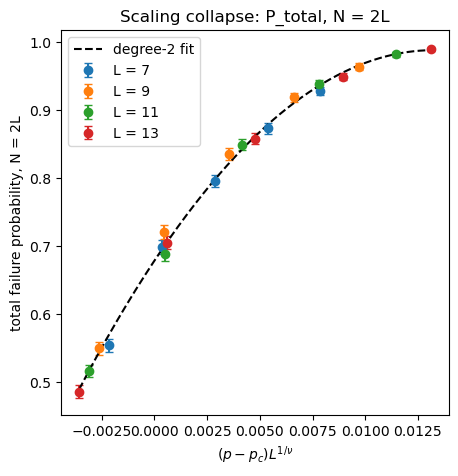

## Fixed-aspect thresholds (window (0.005, 0.007), L >= 7, degree 2)

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| P_total, N = L | 2 | 0.00547(5) | 0.547(5) | 1.4(1) | 1.35 | 0.163 |
| P_total, N = 2L | 2 | 0.00543(4) | 0.543(4) | 1.21(9) | 1.34 | 0.168 |

| sizes | crossing, N = L (%) | crossing, N = 2L (%) |
| --- | --- | --- |
| 5/7 | 0.516 [0.506, 0.525] | 0.516 [0.506, 0.526] |
| 7/9 | 0.505 [0.489, 0.517] | 0.508 [0.490, 0.524] |
| 9/11 | 0.584 [0.575, 0.598] | 0.585 [0.575, 0.598] |
| 11/13 | 0.532 [0.520, 0.568] | 0.532 [0.521, 0.545] |

In [3]:
ASPECT_WINDOW = (0.005, 0.007)
aspect_fits = []
for label, scan in aspect_scans.items():
    try:
        fit = fit_finite_size_scaling(scan, label=f"P_total, {label}", fit_p_range=ASPECT_WINDOW,
                                      min_L=MIN_L, polynomial_degree=2)
        aspect_fits.append(fit)
        display_finite_size_scaling_fit(fit, f"total failure probability, {label}")
    except Exception as err:
        print(f"{label}: fit failed ({err})")
display_fit_summary(aspect_fits, title=f"Fixed-aspect thresholds (window {ASPECT_WINDOW}, L >= {MIN_L}, degree 2)")


def pairwise_crossing(a, b, p_values):
    # first p where curve a (smaller L) stops lying above curve b
    d = a - b
    for j in range(len(p_values) - 1):
        if d[j] > 0 >= d[j + 1]:
            return p_values[j] + d[j] * (p_values[j + 1] - p_values[j]) / (d[j] - d[j + 1])
    return np.nan


rng = np.random.default_rng(0)
p_arr = np.array(P_VALUES)
rows = ["| sizes | " + " | ".join(f"crossing, {label} (%)" for label in aspect_scans) + " |",
        "| --- |" + " --- |" * len(aspect_scans)]
for i in range(len(L_VALUES) - 1):
    row = []
    for scan in aspect_scans.values():
        est = scan.rate()
        c0 = pairwise_crossing(est.values[i], est.values[i + 1], p_arr)
        boots = np.array([pairwise_crossing(est.values[i] + rng.normal(0, est.errors[i]),
                                            est.values[i + 1] + rng.normal(0, est.errors[i + 1]), p_arr)
                          for _ in range(1000)])
        boots = boots[np.isfinite(boots)]
        row.append(f"{100 * c0:.3f} [{100 * np.percentile(boots, 16):.3f}, {100 * np.percentile(boots, 84):.3f}]"
                   if np.isfinite(c0) and boots.size else "–")
    rows.append(f"| {L_VALUES[i]}/{L_VALUES[i + 1]} | " + " | ".join(row) + " |")
display(Markdown("\n".join(rows)))

Own faults per circuit by sector, from the logical-frame snapshots: hub X and hub Z over A's whole history (a probability), and the partners' X and Z faults summed over the `N` partners (an expected count, which can exceed 1). Each is a fixed-aspect quantity, so its crossing shows which sector limits the circuit. Errors are binomial for the hub and Poisson for the partner sums; the partners of one trial are correlated through A, so the latter are lower bounds.

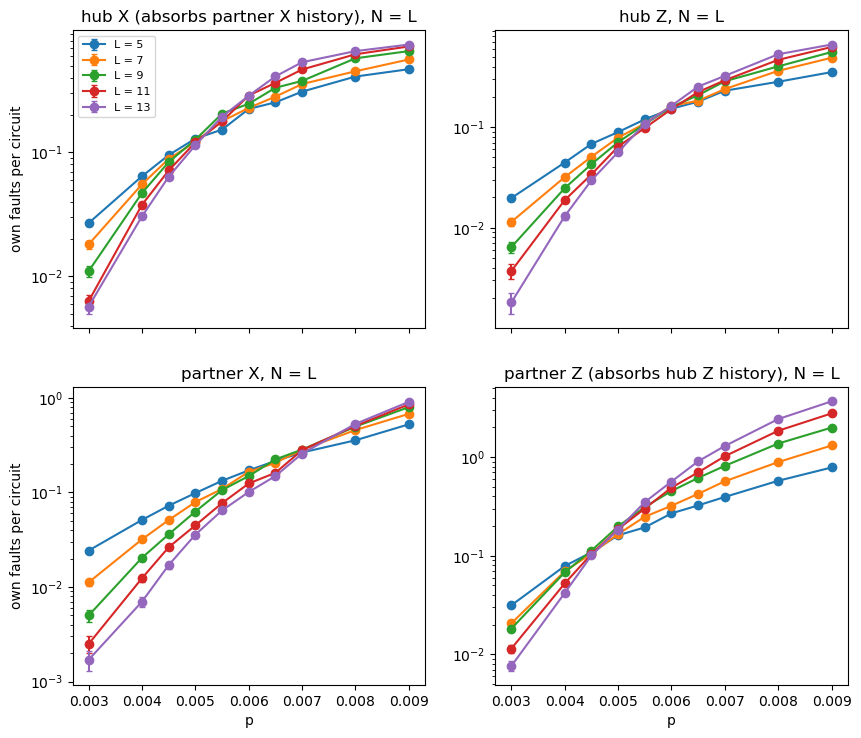

## Per-circuit own-fault crossings by sector (L >= 7, degree 2)

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| hub X (absorbs partner X history), N = L | 2 | 0.00521(6) | 0.521(6) | 1.3(1) | 1.55 | 0.0791 |
| hub Z, N = L | 2 | 0.00566(9) | 0.566(9) | 1.3(2) | 0.82 | 0.655 |
| partner X, N = L | 2 | 0.0075(1) | 0.75(1) | 1.4(1) | 1.53 | 0.0839 |
| partner Z (absorbs hub Z history), N = L | 2 | 0.00475(4) | 0.475(4) | 1.15(7) | 4.05 | 1.88e-07 |
| hub X (absorbs partner X history), N = 2L | 2 | 0.00516(6) | 0.516(6) | 1.18(9) | 0.94 | 0.523 |
| hub Z, N = 2L | 2 | 0.00571(8) | 0.571(8) | 1.3(1) | 0.83 | 0.647 |
| partner X, N = 2L | 2 | 0.00734(8) | 0.734(8) | 1.5(1) | 2.00 | 0.012 |
| partner Z (absorbs hub Z history), N = 2L | 2 | 0.00463(4) | 0.463(4) | 1.18(6) | 8.13 | 7.95e-19 |

In [4]:
SECTOR_KEYS = {"hub_x": "hub_x_own_failures", "hub_z": "hub_z_own_failures",
               "partner_x": "partner_x_own_failures", "partner_z": "partner_z_own_failures"}
SECTOR_LABELS = {"hub_x": "hub X (absorbs partner X history)", "hub_z": "hub Z",
                 "partner_x": "partner X", "partner_z": "partner Z (absorbs hub Z history)"}


def sector_grids(n_index):
    out = {}
    for name, key in SECTOR_KEYS.items():
        values = np.full((len(L_VALUES), len(P_VALUES)), np.nan)
        errors = values.copy()
        for i, L in enumerate(L_VALUES):
            for j, p in enumerate(P_VALUES):
                rec = groups[(GAP, L, p, N_BY_L[L][n_index])]
                count, trials = rec[key], rec["trials"]
                values[i, j] = count / trials
                var = count * (1 - count / trials) if name.startswith("hub") else count
                errors[i, j] = np.sqrt(max(var, 1.0)) / trials
        out[name] = RateEstimate(values, errors)
    return out


sector_scans = {label: rates_as_scan(sector_grids(n_index), L_values=L_VALUES, p_values=P_VALUES, label=label)
                for n_index, label in ((0, "N = L"), (-1, "N = 2L"))}
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5), sharex=True)
for ax, (name, label) in zip(axes.flat, SECTOR_LABELS.items()):
    est = sector_scans["N = L"].rate(name)
    for i, L in enumerate(L_VALUES):
        ax.errorbar(P_VALUES, est.values[i], yerr=est.errors[i], fmt="o-", capsize=2, label=f"L = {L}")
    ax.set_yscale("log")
    ax.set_title(f"{label}, N = L")
for ax in axes[1]:
    ax.set_xlabel("p")
for ax in axes[:, 0]:
    ax.set_ylabel("own faults per circuit")
axes[0, 0].legend(fontsize=8)
plt.show()

SECTOR_WINDOW = {"hub_x": (0.0045, 0.0065), "hub_z": (0.0045, 0.0065), "partner_x": (0.006, 0.009), "partner_z": (0.004, 0.006)}
sector_fits = []
for aspect, scan in sector_scans.items():
    for name, label in SECTOR_LABELS.items():
        window = SECTOR_WINDOW[name] if isinstance(SECTOR_WINDOW, dict) else SECTOR_WINDOW
        try:
            sector_fits.append(fit_finite_size_scaling(scan, rate_name=name, label=f"{label}, {aspect}",
                                                       fit_p_range=window, min_L=MIN_L, polynomial_degree=2))
        except Exception as err:
            print(f"{label}, {aspect}: fit failed ({err})")
display_fit_summary(sector_fits, title=f"Per-circuit own-fault crossings by sector (L >= {MIN_L}, degree 2)")

## 2. Per-gate rate

Single-point rates at both CNOT counts, and the exact two-point decay fit. Where neither count is saturated, the decay fit gives `B` near 1 (A's first and last `d` rounds and the warm-up of A's decoder are negligible) and the two single-point rates agree, which justifies `B = 1`. Near threshold `N = 2L` saturates and the decay fit loses its precision, so the headline rate is the single-point value at `N = L`.

In [5]:
rates = hub_rate_grids(groups, GAP, L_VALUES, P_VALUES)   # decay fits and own-fault components


def single_point_grid(n_index):
    values = np.full((len(L_VALUES), len(P_VALUES)), np.nan)
    errors = values.copy()
    for i, L in enumerate(L_VALUES):
        for j, p in enumerate(P_VALUES):
            rec = groups[(GAP, L, p, N_BY_L[L][n_index])]
            if 0 < rec["failures"] < rec["trials"]:
                values[i, j], errors[i, j] = single_point_rate(rec["failures"], rec["trials"], N_BY_L[L][n_index], p_max=1.0)
    return RateEstimate(values, errors)


eps = {"single": single_point_grid(0), "single_2L": single_point_grid(-1), "decay": rates["cnot"]}
rows = ["| L | p | P(N = L) | P(N = 2L) | eps_CNOT (N = L) | eps_CNOT (N = 2L) | eps_CNOT (decay) | B |",
        "| --- | --- | --- | --- | --- | --- | --- | --- |"]
for i, L in enumerate(L_VALUES):
    for j, p in enumerate(P_VALUES):
        recs = [groups[(GAP, L, p, N)] for N in N_BY_L[L]]
        P = [rec["failures"] / rec["trials"] for rec in recs]
        try:
            B = f"{hub_gate_rates(groups, GAP, L, p).cnot.intercept:.3f}"
        except ValueError:
            B = "–"
        cells = [f"{eps[name].values[i, j]:.4g} ± {eps[name].errors[i, j]:.2g}" if np.isfinite(eps[name].values[i, j]) else "–"
                 for name in ("single", "single_2L", "decay")]
        rows.append(f"| {L} | {p:.4f} | {P[0]:.4f} | {P[-1]:.4f} | " + " | ".join(cells) + f" | {B} |")
display(Markdown("\n".join(rows)))

| L | p | P(N = L) | P(N = 2L) | eps_CNOT (N = L) | eps_CNOT (N = 2L) | eps_CNOT (decay) | B |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.0030 | 0.0856 | 0.1553 | 0.01774 ± 0.0006 | 0.01673 ± 0.00043 | 0.01573 ± 0.0011 | 0.990 |
| 5 | 0.0040 | 0.1905 | 0.3475 | 0.04138 ± 0.001 | 0.04179 ± 0.0011 | 0.0422 ± 0.0024 | 1.004 |
| 5 | 0.0045 | 0.2645 | 0.4600 | 0.05959 ± 0.0015 | 0.05976 ± 0.0015 | 0.05992 ± 0.0034 | 1.002 |
| 5 | 0.0050 | 0.3488 | 0.5712 | 0.08222 ± 0.002 | 0.08119 ± 0.0021 | 0.08016 ± 0.0046 | 0.989 |
| 5 | 0.0055 | 0.4145 | 0.6620 | 0.1015 ± 0.0025 | 0.1028 ± 0.0026 | 0.104 ± 0.0058 | 1.014 |
| 5 | 0.0060 | 0.5212 | 0.7583 | 0.137 ± 0.0034 | 0.1324 ± 0.0035 | 0.1278 ± 0.0077 | 0.949 |
| 5 | 0.0065 | 0.5910 | 0.8333 | 0.1637 ± 0.004 | 0.164 ± 0.0044 | 0.1643 ± 0.0097 | 1.004 |
| 5 | 0.0070 | 0.6643 | 0.8701 | 0.1961 ± 0.0048 | 0.1846 ± 0.0051 | 0.1729 ± 0.011 | 0.867 |
| 5 | 0.0080 | 0.7882 | 0.9500 | 0.2669 ± 0.0065 | 0.2588 ± 0.0081 | 0.2507 ± 0.018 | 0.896 |
| 5 | 0.0090 | 0.8818 | 0.9830 | 0.3476 ± 0.0086 | 0.3345 ± 0.013 | 0.3211 ± 0.028 | 0.820 |
| 7 | 0.0030 | 0.0549 | 0.0935 | 0.008034 ± 0.00034 | 0.006987 ± 0.00023 | 0.005939 ± 0.00057 | 0.985 |
| 7 | 0.0040 | 0.1574 | 0.2821 | 0.02416 ± 0.00062 | 0.0234 ± 0.0006 | 0.02263 ± 0.0014 | 0.989 |
| 7 | 0.0045 | 0.2383 | 0.4257 | 0.03814 ± 0.00097 | 0.03883 ± 0.001 | 0.03952 ± 0.0022 | 1.010 |
| 7 | 0.0050 | 0.3344 | 0.5541 | 0.05649 ± 0.0014 | 0.05606 ± 0.0014 | 0.05563 ± 0.0032 | 0.994 |
| 7 | 0.0055 | 0.4442 | 0.6986 | 0.08048 ± 0.002 | 0.08211 ± 0.0022 | 0.08374 ± 0.0047 | 1.025 |
| 7 | 0.0060 | 0.5601 | 0.7958 | 0.1107 ± 0.0028 | 0.1073 ± 0.0029 | 0.1038 ± 0.0065 | 0.947 |
| 7 | 0.0065 | 0.6508 | 0.8731 | 0.1395 ± 0.0035 | 0.1371 ± 0.0039 | 0.1347 ± 0.0086 | 0.961 |
| 7 | 0.0070 | 0.7553 | 0.9282 | 0.1822 ± 0.0046 | 0.1715 ± 0.0053 | 0.1607 ± 0.012 | 0.834 |
| 7 | 0.0080 | 0.8772 | 0.9868 | 0.2589 ± 0.0068 | 0.2661 ± 0.012 | 0.2732 ± 0.024 | 1.146 |
| 7 | 0.0090 | 0.9628 | 0.9987 | 0.3751 ± 0.012 | 0.3768 ± 0.031 | 0.3786 ± 0.064 | 1.041 |
| 9 | 0.0030 | 0.0348 | 0.0703 | 0.003928 ± 0.00021 | 0.004041 ± 0.00015 | 0.004155 ± 0.00037 | 1.002 |
| 9 | 0.0040 | 0.1289 | 0.2581 | 0.01522 ± 0.00042 | 0.01645 ± 0.00042 | 0.01768 ± 0.00094 | 1.023 |
| 9 | 0.0045 | 0.2132 | 0.3922 | 0.0263 ± 0.00067 | 0.02728 ± 0.0007 | 0.02826 ± 0.0016 | 1.018 |
| 9 | 0.0050 | 0.3310 | 0.5497 | 0.04368 ± 0.0011 | 0.04335 ± 0.0011 | 0.04302 ± 0.0025 | 0.994 |
| 9 | 0.0055 | 0.4739 | 0.7208 | 0.06888 ± 0.0017 | 0.06843 ± 0.0018 | 0.06797 ± 0.004 | 0.991 |
| 9 | 0.0060 | 0.5919 | 0.8357 | 0.0948 ± 0.0024 | 0.09545 ± 0.0027 | 0.09611 ± 0.0059 | 1.013 |
| 9 | 0.0065 | 0.7059 | 0.9191 | 0.1271 ± 0.0033 | 0.1304 ± 0.004 | 0.1336 ± 0.0087 | 1.070 |
| 9 | 0.0070 | 0.7974 | 0.9640 | 0.1626 ± 0.0043 | 0.1686 ± 0.0061 | 0.1747 ± 0.013 | 1.140 |
| 9 | 0.0080 | 0.9398 | 0.9967 | 0.2683 ± 0.008 | 0.2717 ± 0.018 | 0.2752 ± 0.037 | 1.089 |
| 9 | 0.0090 | 0.9855 | 0.9993 | 0.3755 ± 0.015 | 0.3339 ± 0.037 | 0.2896 ± 0.081 | 0.314 |
| 11 | 0.0030 | 0.0198 | 0.0414 | 0.001816 ± 0.00013 | 0.00192 ± 9.4e-05 | 0.002024 ± 0.00023 | 1.002 |
| 11 | 0.0040 | 0.0970 | 0.1876 | 0.009233 ± 0.0003 | 0.0094 ± 0.00024 | 0.009568 ± 0.00057 | 1.004 |
| 11 | 0.0045 | 0.1865 | 0.3231 | 0.01859 ± 0.00048 | 0.01758 ± 0.00045 | 0.01656 ± 0.001 | 0.978 |
| 11 | 0.0050 | 0.3007 | 0.5162 | 0.03199 ± 0.00082 | 0.03246 ± 0.00084 | 0.03294 ± 0.0019 | 1.011 |
| 11 | 0.0055 | 0.4422 | 0.6881 | 0.05169 ± 0.0013 | 0.05158 ± 0.0014 | 0.05146 ± 0.003 | 0.997 |
| 11 | 0.0060 | 0.6063 | 0.8494 | 0.08125 ± 0.0021 | 0.08245 ± 0.0024 | 0.08364 ± 0.0051 | 1.029 |
| 11 | 0.0065 | 0.7253 | 0.9381 | 0.1108 ± 0.0029 | 0.1188 ± 0.0039 | 0.1267 ± 0.0082 | 1.218 |
| 11 | 0.0070 | 0.8503 | 0.9823 | 0.1586 ± 0.0043 | 0.1676 ± 0.0072 | 0.1765 ± 0.015 | 1.267 |
| 11 | 0.0080 | 0.9759 | 0.9987 | 0.2874 ± 0.011 | 0.2599 ± 0.024 | 0.2314 ± 0.051 | 0.435 |
| 11 | 0.0090 | 0.9960 | 1.0000 | 0.3949 ± 0.022 | – | – | – |
| 13 | 0.0030 | 0.0141 | 0.0228 | 0.001092 ± 9.2e-05 | 0.0008867 ± 5.9e-05 | 0.0006816 ± 0.00015 | 0.995 |
| 13 | 0.0040 | 0.0763 | 0.1506 | 0.006087 ± 0.00022 | 0.00626 ± 0.00016 | 0.006434 ± 0.00039 | 1.005 |
| 13 | 0.0045 | 0.1627 | 0.3021 | 0.01356 ± 0.00035 | 0.01374 ± 0.00035 | 0.01391 ± 0.00079 | 1.005 |
| 13 | 0.0050 | 0.2813 | 0.4859 | 0.02509 ± 0.00064 | 0.02527 ± 0.00066 | 0.02544 ± 0.0015 | 1.005 |
| 13 | 0.0055 | 0.4528 | 0.7052 | 0.04532 ± 0.0012 | 0.0459 ± 0.0012 | 0.04647 ± 0.0027 | 1.016 |
| 13 | 0.0060 | 0.6053 | 0.8581 | 0.06902 ± 0.0018 | 0.07236 ± 0.0021 | 0.07568 ± 0.0045 | 1.098 |
| 13 | 0.0065 | 0.7772 | 0.9494 | 0.1091 ± 0.0029 | 0.1084 ± 0.0037 | 0.1077 ± 0.008 | 0.980 |
| 13 | 0.0070 | 0.8923 | 0.9894 | 0.1575 ± 0.0046 | 0.1606 ± 0.008 | 0.1636 ± 0.017 | 1.099 |
| 13 | 0.0080 | 0.9823 | 0.9987 | 0.2668 ± 0.011 | 0.2248 ± 0.021 | 0.1804 ± 0.046 | 0.235 |
| 13 | 0.0090 | 0.9980 | 1.0000 | 0.3801 ± 0.028 | – | – | – |

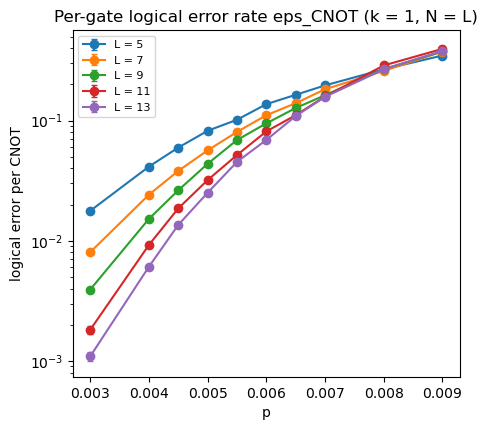

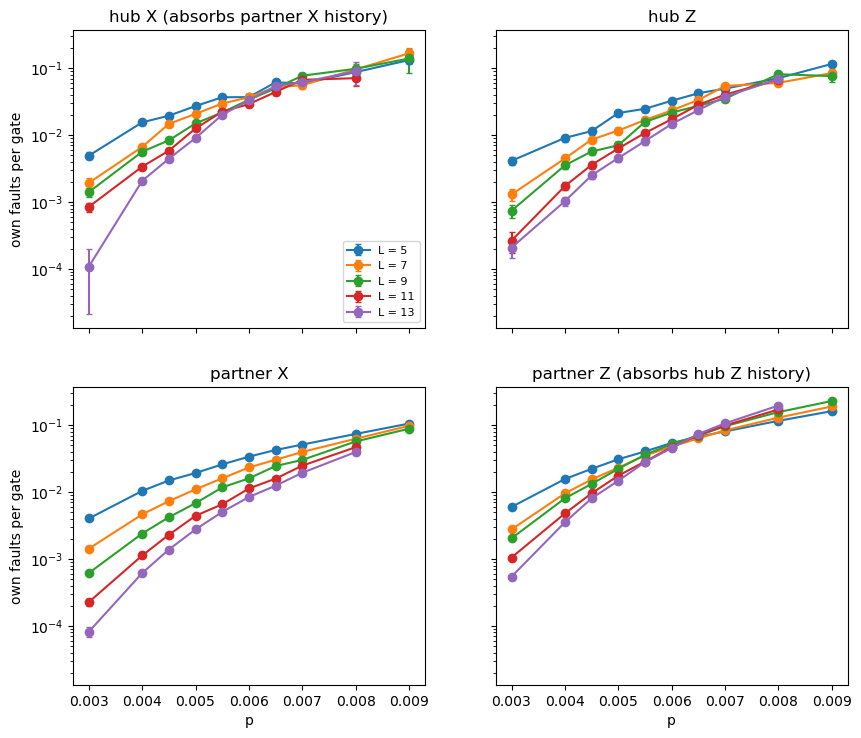

Over the whole scan: 139337 failing trials, 139778 with an own fault; readout cleanup failures 552 and snapshot cleanup failures 2011 in 392155 trials.

In [6]:
fig, ax = plt.subplots(figsize=(5, 4.5))
for i, L in enumerate(L_VALUES):
    ax.errorbar(P_VALUES, eps["single"].values[i], yerr=eps["single"].errors[i], fmt="o-", capsize=2, label=f"L = {L}")
ax.set_yscale("log")
ax.set_xlabel("p")
ax.set_ylabel("logical error per CNOT")
ax.set_title(f"Per-gate logical error rate eps_CNOT (k = {GAP}, N = L)")
ax.legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 8.5), sharex=True, sharey=True)
for ax, (name, label) in zip(axes.flat, SECTOR_LABELS.items()):
    est = rates[name]
    for i, L in enumerate(L_VALUES):
        ax.errorbar(P_VALUES, est.values[i], yerr=est.errors[i], fmt="o-", capsize=2, label=f"L = {L}")
    ax.set_yscale("log")
    ax.set_title(label)
for ax in axes[1]:
    ax.set_xlabel("p")
for ax in axes[:, 0]:
    ax.set_ylabel("own faults per gate")
axes[0, 0].legend(fontsize=8)
plt.show()

total_trials = sum(g["trials"] for g in groups.values())
display(Markdown(
    f"Over the whole scan: {int(sum(g['failures'] for g in groups.values()))} failing trials, "
    f"{int(sum(g['own_failure_trials'] for g in groups.values()))} with an own fault; readout cleanup failures "
    f"{int(sum(g['cleanup_failures'] for g in groups.values()))} and snapshot cleanup failures "
    f"{int(sum(g['snapshot_cleanup_failures'] for g in groups.values()))} in {int(total_trials)} trials."
))

Snapshot check. A's Z errors are copied into every later partner, so the partners' final Z counts should grow with the partner index while their own-fault counts stay flat. Counts are pooled over `p` at `N = 2L`; slopes are per unit index, relative to the mean count (Poisson errors).

In [7]:
profile_keys = {"final Z": "partner_z_failures_by_index", "own Z": "partner_z_own_failures_by_index",
                "own X": "partner_x_own_failures_by_index"}
rows = ["| L | N | " + " | ".join(f"{name} slope" for name in profile_keys) + " |",
        "| --- | --- |" + " --- |" * len(profile_keys)]
for L in L_VALUES:
    N_prof = max(N_BY_L[L])
    j_idx = np.arange(1, N_prof + 1)
    centred = j_idx - j_idx.mean()
    cells = []
    for key in profile_keys.values():
        counts = sum(np.asarray(groups[(GAP, L, p, N_prof)][key], dtype=float) for p in P_VALUES)
        mean = counts.mean()
        slope = np.polyfit(j_idx, counts / mean, 1)[0]
        err = np.sqrt(np.sum(centred ** 2 * counts)) / mean / np.sum(centred ** 2)
        cells.append(f"{slope:+.4f} ± {err:.4f}")
    rows.append(f"| {L} | {N_prof} | " + " | ".join(cells) + " |")
display(Markdown("\n".join(rows)))

| L | N | final Z slope | own Z slope | own X slope |
| --- | --- | --- | --- | --- |
| 5 | 10 | +0.1435 ± 0.0018 | +0.0101 ± 0.0032 | -0.0008 ± 0.0040 |
| 7 | 14 | +0.1038 ± 0.0011 | +0.0120 ± 0.0020 | +0.0014 ± 0.0029 |
| 9 | 18 | +0.0795 ± 0.0008 | +0.0157 ± 0.0013 | -0.0011 ± 0.0022 |
| 11 | 22 | +0.0655 ± 0.0006 | +0.0140 ± 0.0009 | -0.0008 ± 0.0019 |
| 13 | 26 | +0.0533 ± 0.0004 | +0.0113 ± 0.0007 | -0.0004 ± 0.0016 |

## 3. Suppression factor `Lambda_CNOT` and per-gate crossing

At a fixed density `P_total(N = cL) ≈ cL eps_CNOT` for small rates, so `P_total` is flat in `L` where `Lambda_CNOT ≈ (L+2)/L`, not where it equals 1. The `Lambda_CNOT = 1` point and the crossing of `eps_CNOT` therefore lie above the fixed-aspect threshold at these sizes, as for the per-round memory rate in Stage 1.

In [8]:
rows = ["| p | Lambda_CNOT (N = L) | Lambda_CNOT (decay) | pairwise eps_L / eps_(L+2), N = L |", "| --- | --- | --- | --- |"]
lam = []
for j, p in enumerate(P_VALUES):
    try:
        lf = fit_lambda(L_VALUES, eps["single"].values[:, j], eps["single"].errors[:, j])
    except ValueError:
        continue
    lam.append((p, lf.Lambda))
    try:
        ld = fit_lambda(L_VALUES, eps["decay"].values[:, j], eps["decay"].errors[:, j])
        decay_text = f"{ld.Lambda:.3f} ± {ld.Lambda_error:.3f}"
    except ValueError:
        decay_text = "–"
    pairs = ", ".join(f"{a}/{b}: {r:.2f}±{e:.2f}"
                      for a, b, r, e in lambda_ratios(L_VALUES, eps["single"].values[:, j], eps["single"].errors[:, j]))
    rows.append(f"| {p:.4f} | {lf.Lambda:.3f} ± {lf.Lambda_error:.3f} | {decay_text} | {pairs} |")
display(Markdown("\n".join(rows)))
lam = np.array(lam)
crossing = None
for (p0, l0), (p1, l1) in zip(lam[:-1], lam[1:]):
    if (l0 - 1) * (l1 - 1) <= 0 and l0 != l1:
        crossing = p0 + (1 - l0) * (p1 - p0) / (l1 - l0)
        break
display(Markdown(f"`Lambda_CNOT = 1` near p = {crossing:.4f}" if crossing else "`Lambda_CNOT` does not cross 1 on this grid"))

| p | Lambda_CNOT (N = L) | Lambda_CNOT (decay) | pairwise eps_L / eps_(L+2), N = L |
| --- | --- | --- | --- |
| 0.0030 | 2.068 ± 0.036 | 2.012 ± 0.070 | 5/7: 2.21±0.12, 7/9: 2.05±0.14, 9/11: 2.16±0.19, 11/13: 1.66±0.18 |
| 0.0040 | 1.621 ± 0.015 | 1.590 ± 0.029 | 5/7: 1.71±0.06, 7/9: 1.59±0.06, 9/11: 1.65±0.07, 11/13: 1.52±0.07 |
| 0.0045 | 1.445 ± 0.012 | 1.458 ± 0.026 | 5/7: 1.56±0.06, 7/9: 1.45±0.05, 9/11: 1.41±0.05, 11/13: 1.37±0.05 |
| 0.0050 | 1.343 ± 0.011 | 1.326 ± 0.024 | 5/7: 1.46±0.05, 7/9: 1.29±0.05, 9/11: 1.37±0.05, 11/13: 1.27±0.05 |
| 0.0055 | 1.228 ± 0.010 | 1.234 ± 0.022 | 5/7: 1.26±0.04, 7/9: 1.17±0.04, 9/11: 1.33±0.05, 11/13: 1.14±0.04 |
| 0.0060 | 1.183 ± 0.009 | 1.135 ± 0.022 | 5/7: 1.24±0.04, 7/9: 1.17±0.04, 9/11: 1.17±0.04, 11/13: 1.18±0.04 |
| 0.0065 | 1.111 ± 0.009 | 1.095 ± 0.023 | 5/7: 1.17±0.04, 7/9: 1.10±0.04, 9/11: 1.15±0.04, 11/13: 1.02±0.04 |
| 0.0070 | 1.061 ± 0.009 | 1.000 ± 0.026 | 5/7: 1.08±0.04, 7/9: 1.12±0.04, 9/11: 1.03±0.04, 11/13: 1.01±0.04 |
| 0.0080 | 0.989 ± 0.010 | 1.026 ± 0.047 | 5/7: 1.03±0.04, 7/9: 0.97±0.04, 9/11: 0.93±0.04, 11/13: 1.08±0.06 |
| 0.0090 | 0.968 ± 0.013 | 0.976 ± 0.120 | 5/7: 0.93±0.04, 7/9: 1.00±0.05, 9/11: 0.95±0.07, 11/13: 1.04±0.10 |

`Lambda_CNOT = 1` near p = 0.0079

#### Finite-size scaling fit: eps_CNOT (N = L)

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.006, 0.009]$ and $L \in [7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.0079(2) |
| $p_c$ (%) | 0.79(2) |
| $\nu$ | 1.9(3) |
| $A$ | 0.25(2) |
| $B$ | 33(6) |
| $C$ | 1069(323) |
| $\chi^2 / \mathrm{dof}$ | 17.28 / 15 = 1.15 |
| goodness-of-fit $p$-value | 0.302 |

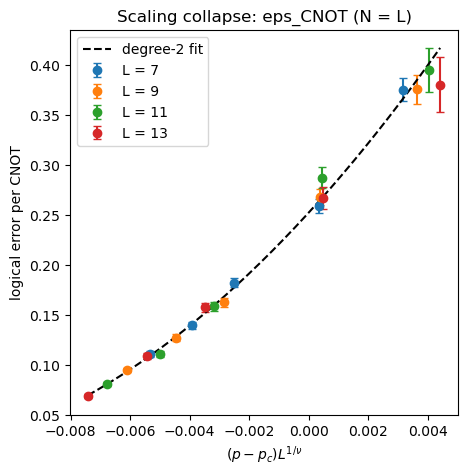

## Per-gate crossing (window (0.006, 0.009), L >= 7, degree 2)

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| eps_CNOT (N = L) | 2 | 0.0079(2) | 0.79(2) | 1.9(3) | 1.15 | 0.302 |

In [9]:
EPS_WINDOW = (0.006, 0.009)
eps_scan = rates_as_scan({"cnot": eps["single"]}, L_values=L_VALUES, p_values=P_VALUES, label=f"hub k={GAP}")
eps_fits = []
try:
    fit = fit_finite_size_scaling(eps_scan, rate_name="cnot", label="eps_CNOT (N = L)", fit_p_range=EPS_WINDOW,
                                  min_L=MIN_L, polynomial_degree=2)
    eps_fits.append(fit)
    display_finite_size_scaling_fit(fit, "logical error per CNOT")
except Exception as err:
    print(f"eps_CNOT: fit failed ({err})")
display_fit_summary(eps_fits, title=f"Per-gate crossing (window {EPS_WINDOW}, L >= {MIN_L}, degree 2)")

Robustness: each crossing over several windows, polynomial degrees 2 and 3, and minimum size 5 or 7. A fit is dropped if `p_c` sits on a window edge (the fit bound) or its goodness-of-fit p-value is below 0.05.

In [10]:
WINDOWS = {"aspect": [(0.005, 0.007), (0.004, 0.007), (0.004, 0.0065), (0.0045, 0.0065), (0.0045, 0.007), (0.004, 0.006), (0.0045, 0.006), (0.005, 0.0065), (0.005, 0.006)], "eps": [(0.005, 0.009), (0.0055, 0.009), (0.006, 0.009), (0.0055, 0.008), (0.006, 0.008), (0.005, 0.008), (0.0065, 0.009)], "hub_x": [(0.004, 0.0065), (0.0045, 0.0065), (0.0045, 0.006), (0.004, 0.006), (0.0045, 0.007), (0.005, 0.0065)], "hub_z": [(0.0045, 0.0065), (0.005, 0.0065), (0.005, 0.007), (0.0045, 0.007), (0.004, 0.007), (0.005, 0.008)], "partner_x": [(0.0065, 0.009), (0.006, 0.009), (0.007, 0.009), (0.0065, 0.008), (0.006, 0.008)], "partner_z": [(0.003, 0.0055), (0.004, 0.0055), (0.004, 0.006), (0.0045, 0.0055), (0.0045, 0.006), (0.003, 0.006)]}   # keys: "aspect", "eps", and sector names
targets = {f"P_total, {label}": (aspect_scans[label], "overall", "aspect") for label in aspect_scans}
for aspect, scan in sector_scans.items():
    targets.update({f"{SECTOR_LABELS[name]}, {aspect}": (scan, name, name) for name in SECTOR_LABELS})
targets["eps_CNOT (N = L)"] = (eps_scan, "cnot", "eps")
robust = {}
rows = ["| quantity | accepted fits | p_c range (%) | median p_c (%) | dropped: on edge / bad fit |", "| --- | --- | --- | --- | --- |"]
for label, (target_scan, rate_name, group) in targets.items():
    if group not in WINDOWS:
        continue
    accepted, edge, bad = [], 0, 0
    for window_try in WINDOWS[group]:
        for degree in (2, 3):
            for min_L in (5, 7):
                try:
                    fit = fit_finite_size_scaling(target_scan, rate_name=rate_name, label=label, fit_p_range=window_try,
                                                  min_L=min_L, polynomial_degree=degree)
                except Exception:
                    bad += 1
                    continue
                if min(abs(fit.pc - window_try[0]), abs(fit.pc - window_try[1])) < 2e-5:
                    edge += 1
                elif fit.p_value < 0.05:
                    bad += 1
                else:
                    accepted.append(fit.pc)
    robust[label] = np.array(accepted)
    span = (f"{100 * min(accepted):.3f} – {100 * max(accepted):.3f} | {100 * np.median(accepted):.3f}"
            if accepted else "– | –")
    rows.append(f"| {label} | {len(accepted)} | {span} | {edge} / {bad} |")
display(Markdown("\n".join(rows)))

| quantity | accepted fits | p_c range (%) | median p_c (%) | dropped: on edge / bad fit |
| --- | --- | --- | --- | --- |
| P_total, N = L | 10 | 0.545 – 0.555 | 0.548 | 0 / 26 |
| P_total, N = 2L | 8 | 0.533 – 0.551 | 0.542 | 0 / 28 |
| hub X (absorbs partner X history), N = L | 6 | 0.517 – 0.522 | 0.521 | 0 / 18 |
| hub Z, N = L | 24 | 0.566 – 0.578 | 0.572 | 0 / 0 |
| partner X, N = L | 9 | 0.731 – 0.746 | 0.740 | 1 / 10 |
| partner Z (absorbs hub Z history), N = L | 0 | – | – | 0 / 24 |
| hub X (absorbs partner X history), N = 2L | 18 | 0.508 – 0.520 | 0.513 | 0 / 6 |
| hub Z, N = 2L | 22 | 0.566 – 0.576 | 0.573 | 0 / 2 |
| partner X, N = 2L | 0 | – | – | 1 / 19 |
| partner Z (absorbs hub Z history), N = 2L | 0 | – | – | 0 / 24 |
| eps_CNOT (N = L) | 26 | 0.764 – 0.809 | 0.790 | 2 / 0 |

## 4. Comparison with `k = d`

The first Stage-2 pass used `k = d` (one gate per `d + 1` hub rounds, `N` = 1, 2, 4, 8). At `L = 5` a small fixed `k` is close to that schedule; at larger `L` the fixed gap is much denser. The ratio is `eps_CNOT(k) / eps_CNOT(k = d)` at the same `(L, p)`, with the single-point rate at `N = L` for `k` and the decay fit for `k = d`.

In [11]:
groups_d = load_hub_records(HUB_ROOT / "k_d")
P_D = sorted({key[2] for key in groups_d})
rates_d = hub_rate_grids(groups_d, "d", L_VALUES, P_D)
common = [p for p in P_VALUES if any(np.isclose(p, P_D))]
rows = ["| L | p | eps_CNOT (k = " + GAP + ") | eps_CNOT (k = d) | ratio |", "| --- | --- | --- | --- | --- |"]
for i, L in enumerate(L_VALUES):
    for p in common:
        j, jd = P_VALUES.index(p), int(np.argmin(np.abs(np.array(P_D) - p)))
        a, b = eps["single"].values[i, j], rates_d["cnot"].values[i, jd]
        if np.isfinite(a) and np.isfinite(b):
            rows.append(f"| {L} | {p:.4f} | {a:.4g} | {b:.4g} | {a / b:.2f} |")
display(Markdown("\n".join(rows)))

| L | p | eps_CNOT (k = 1) | eps_CNOT (k = d) | ratio |
| --- | --- | --- | --- | --- |
| 5 | 0.0040 | 0.04138 | 0.04041 | 1.02 |
| 5 | 0.0050 | 0.08222 | 0.07535 | 1.09 |
| 5 | 0.0060 | 0.137 | 0.1201 | 1.14 |
| 5 | 0.0070 | 0.1961 | 0.1902 | 1.03 |
| 5 | 0.0080 | 0.2669 | 0.2617 | 1.02 |
| 5 | 0.0090 | 0.3476 | 0.3562 | 0.98 |
| 7 | 0.0040 | 0.02416 | 0.02128 | 1.14 |
| 7 | 0.0050 | 0.05649 | 0.05266 | 1.07 |
| 7 | 0.0060 | 0.1107 | 0.102 | 1.09 |
| 7 | 0.0070 | 0.1822 | 0.1673 | 1.09 |
| 7 | 0.0080 | 0.2589 | 0.246 | 1.05 |
| 7 | 0.0090 | 0.3751 | 0.3338 | 1.12 |
| 9 | 0.0040 | 0.01522 | 0.01279 | 1.19 |
| 9 | 0.0050 | 0.04368 | 0.03639 | 1.20 |
| 9 | 0.0060 | 0.0948 | 0.07938 | 1.19 |
| 9 | 0.0070 | 0.1626 | 0.1469 | 1.11 |
| 9 | 0.0080 | 0.2683 | 0.236 | 1.14 |
| 9 | 0.0090 | 0.3755 | 0.3359 | 1.12 |
| 11 | 0.0040 | 0.009233 | 0.006577 | 1.40 |
| 11 | 0.0050 | 0.03199 | 0.02174 | 1.47 |
| 11 | 0.0060 | 0.08125 | 0.05568 | 1.46 |
| 11 | 0.0070 | 0.1586 | 0.1145 | 1.39 |
| 11 | 0.0080 | 0.2874 | 0.2046 | 1.40 |
| 11 | 0.0090 | 0.3949 | 0.3112 | 1.27 |
| 13 | 0.0040 | 0.006087 | 0.003568 | 1.71 |
| 13 | 0.0050 | 0.02509 | 0.01472 | 1.70 |
| 13 | 0.0060 | 0.06902 | 0.04183 | 1.65 |
| 13 | 0.0070 | 0.1575 | 0.1003 | 1.57 |
| 13 | 0.0080 | 0.2668 | 0.1849 | 1.44 |
| 13 | 0.0090 | 0.3801 | 0.3033 | 1.25 |

## 5. Summary

In [12]:
lines = ["| Quantity | Estimate |", "| --- | --- |"]
for fit in aspect_fits + sector_fits + eps_fits:
    lines.append(f"| crossing, {fit.label} (window {fit.fit_p_range}, L >= {fit.min_L}, degree 2) | "
                 f"p_c = {100 * fit.pc:.3f} ± {100 * fit.pc_error:.3f} % (chi2/dof = {fit.chi2:.1f}/{fit.dof}, p-value {fit.p_value:.2f}) |")
for label, values in robust.items():
    if values.size:
        lines.append(f"| crossing range over fit choices, {label} | {100 * values.min():.3f} – {100 * values.max():.3f} % ({values.size} fits) |")
    else:
        lines.append(f"| crossing range over fit choices, {label} | no accepted fit |")
if crossing:
    lines.append(f"| Lambda_CNOT = 1 (N = L) | p ≈ {crossing:.4f} |")
for p, value in lam:
    lines.append(f"| Lambda_CNOT at p = {p:.4f} | {value:.2f} |")
display(Markdown("\n".join(lines)))

| Quantity | Estimate |
| --- | --- |
| crossing, P_total, N = L (window (0.005, 0.007), L >= 7, degree 2) | p_c = 0.547 ± 0.005 % (chi2/dof = 20.2/15, p-value 0.16) |
| crossing, P_total, N = 2L (window (0.005, 0.007), L >= 7, degree 2) | p_c = 0.543 ± 0.004 % (chi2/dof = 20.1/15, p-value 0.17) |
| crossing, hub X (absorbs partner X history), N = L (window (0.0045, 0.0065), L >= 7, degree 2) | p_c = 0.521 ± 0.006 % (chi2/dof = 23.2/15, p-value 0.08) |
| crossing, hub Z, N = L (window (0.0045, 0.0065), L >= 7, degree 2) | p_c = 0.566 ± 0.009 % (chi2/dof = 12.3/15, p-value 0.66) |
| crossing, partner X, N = L (window (0.006, 0.009), L >= 7, degree 2) | p_c = 0.746 ± 0.010 % (chi2/dof = 23.0/15, p-value 0.08) |
| crossing, partner Z (absorbs hub Z history), N = L (window (0.004, 0.006), L >= 7, degree 2) | p_c = 0.475 ± 0.004 % (chi2/dof = 60.7/15, p-value 0.00) |
| crossing, hub X (absorbs partner X history), N = 2L (window (0.0045, 0.0065), L >= 7, degree 2) | p_c = 0.516 ± 0.006 % (chi2/dof = 14.0/15, p-value 0.52) |
| crossing, hub Z, N = 2L (window (0.0045, 0.0065), L >= 7, degree 2) | p_c = 0.571 ± 0.008 % (chi2/dof = 12.4/15, p-value 0.65) |
| crossing, partner X, N = 2L (window (0.006, 0.009), L >= 7, degree 2) | p_c = 0.734 ± 0.008 % (chi2/dof = 30.0/15, p-value 0.01) |
| crossing, partner Z (absorbs hub Z history), N = 2L (window (0.004, 0.006), L >= 7, degree 2) | p_c = 0.463 ± 0.004 % (chi2/dof = 121.9/15, p-value 0.00) |
| crossing, eps_CNOT (N = L) (window (0.006, 0.009), L >= 7, degree 2) | p_c = 0.788 ± 0.019 % (chi2/dof = 17.3/15, p-value 0.30) |
| crossing range over fit choices, P_total, N = L | 0.545 – 0.555 % (10 fits) |
| crossing range over fit choices, P_total, N = 2L | 0.533 – 0.551 % (8 fits) |
| crossing range over fit choices, hub X (absorbs partner X history), N = L | 0.517 – 0.522 % (6 fits) |
| crossing range over fit choices, hub Z, N = L | 0.566 – 0.578 % (24 fits) |
| crossing range over fit choices, partner X, N = L | 0.731 – 0.746 % (9 fits) |
| crossing range over fit choices, partner Z (absorbs hub Z history), N = L | no accepted fit |
| crossing range over fit choices, hub X (absorbs partner X history), N = 2L | 0.508 – 0.520 % (18 fits) |
| crossing range over fit choices, hub Z, N = 2L | 0.566 – 0.576 % (22 fits) |
| crossing range over fit choices, partner X, N = 2L | no accepted fit |
| crossing range over fit choices, partner Z (absorbs hub Z history), N = 2L | no accepted fit |
| crossing range over fit choices, eps_CNOT (N = L) | 0.764 – 0.809 % (26 fits) |
| Lambda_CNOT = 1 (N = L) | p ≈ 0.0079 |
| Lambda_CNOT at p = 0.0030 | 2.07 |
| Lambda_CNOT at p = 0.0040 | 1.62 |
| Lambda_CNOT at p = 0.0045 | 1.45 |
| Lambda_CNOT at p = 0.0050 | 1.34 |
| Lambda_CNOT at p = 0.0055 | 1.23 |
| Lambda_CNOT at p = 0.0060 | 1.18 |
| Lambda_CNOT at p = 0.0065 | 1.11 |
| Lambda_CNOT at p = 0.0070 | 1.06 |
| Lambda_CNOT at p = 0.0080 | 0.99 |
| Lambda_CNOT at p = 0.0090 | 0.97 |

## Findings (`k = 1`, first local scan)

Scan: 100 points and 3.9e5 trials, 1.8 h on 8 threads.

- Sizes and rates: `L = 5-13`, `p = 0.3-0.9%`.
- CNOT counts: `N = L` and `N = 2L`.
- Each point is capped at 1500 failures or 10^4 trials.

**Fixed-aspect threshold.**

- `P_total` crosses at 0.547(5)% for `N = L` and at 0.543(4)% for `N = 2L` (window [0.5, 0.7]%, `L >= 7`, degree 2).
- Accepted fits span 0.533-0.555% over windows, degrees, and minimum `L`. Most fits that include `L = 5` are rejected.
- With `B ≈ 1`, `P(2L) = 1 - (1 - P(L))^2`. The two aspect ratios therefore cross at the same `p` in expectation, so `N = 2L` is an independent replica, not a test of the aspect ratio.
- Pairwise crossings are 0.52, 0.51, 0.58, and 0.53% for `L = 5/7` through `11/13`.
  - The zig-zag comes from `L = 9` doing relatively worse at both aspect ratios, which are independent runs.
  - Cleanup failures also concentrate at `L = 9`, here and in earlier scans.
- This threshold is 0.57 of the `k = d` threshold (0.958%) and 0.31 of the memory threshold (1.77%).

**Limiting sectors (own faults per circuit).**

- Crossings: hub X 0.51-0.52%, hub Z 0.57%, partner X 0.73-0.75%.
- Partner Z, summed over partners, has no acceptable scaling fit (main fits 0.46-0.48%, `chi2/dof` 4-8). It is flat in `L` at 0.45% and grows with `L` from 0.5% on.
- The two absorbing sectors therefore cross below the total, as at `k = d`.
- Inference: the total is a sum over sectors, so its crossing should move toward the lowest sector crossing as `L` grows. The asymptotic threshold may then be nearer 0.5% than 0.55%. Testing this needs `L >= 15`.

**Per-gate rate and `Lambda_CNOT`.**

- The decay fit supports `B = 1` wherever it can be tested:
  - `B = 0.95-1.03` for `p <= 0.6%` (one point at 1.10);
  - single-point rates at `N = L` and `N = 2L` agree (30 points, `sum z^2 = 26.3`).
- Above 0.65%, `N = 2L` saturates and the decay fit is unusable.

| `eps_CNOT` (`N = L`) | p = 0.4% | p = 0.5% | p = 0.6% |
| --- | --- | --- | --- |
| L = 5 | 0.041 | 0.082 | 0.137 |
| L = 9 | 0.0152 | 0.044 | 0.095 |
| L = 13 | 0.0061 | 0.025 | 0.069 |
| `Lambda_CNOT` | 1.62(2) | 1.34(1) | 1.18(1) |

- `Lambda_CNOT` is 2.07(4) at 0.3% and reaches 1 near 0.79%.
- The `eps_CNOT` crossing is in the same place: 0.788(19)%, range 0.764-0.809%.
- The gap to the fixed-aspect threshold comes from the per-gate normalization (Section 3). At 0.55%, `Lambda_CNOT = 1.23`.

**Comparison with `k = d`.**

- Ratio `eps_CNOT(k = 1) / eps_CNOT(k = d)` at equal `(L, p)`, `p <= 0.6%`:
  - `L = 5-7`: 1.0-1.15;
  - `L = 9`: 1.2;
  - `L = 11`: 1.4-1.5;
  - `L = 13`: 1.65-1.7.
- `Lambda_CNOT` at 0.4% and 0.6%: 1.62 and 1.18 here, against 1.82 and 1.31 at `k = d`.
- A's data noise per sector and round:
  - `k = 1`: 3.33p, of which 80% comes from gates;
  - `k = d`: 1.2p at `L = 9`.
- This scan does not separate that noise budget from the merges. The idle control (`GATE_MODE=idle`) would.

**Propagation and stationarity.**

- Final partner Z counts grow by 5-14% of their mean per partner index, because A's Z errors are copied forward.
- Partner own-X counts are flat in the index.
- Partner own-Z counts rise by 1.0-1.6% per index, significantly at every `L`. At `k = d` they were flat.
- Inference: later partners absorb an A Z history with more residual errors, so A is not stationary over the circuit.
- The effect is too small to show in the total rate (the `N = L` vs `N = 2L` check above).

**Snapshots and cleanup.**

- Trials with an own fault outnumber failing trials by 0.3%. A snapshot frame can record a logical on A at gate time that A's decoder later undoes. That logical then counts as an own fault of the partner.
- Readout cleanup failed in 552 of 3.9e5 trials, at most 3.4% (`L = 9`, `p = 0.9%`, `N = 2L`).
- Snapshot cleanup failed in 2011 trials, at most 5.5e-3 per CNOT, at the same point.
- Both are concentrated at `L = 9`.